# 05 – Evaluation

**Project:** Energy-Aware Early Fault Detection in Semiconductor Wafer Fabrication (UCI SECOM)

**Energy cost = FN × C_FN + FP × C_FP** (`src/cost_metric.py`)

- **FN – missed fault:** a defective wafer continues through the remaining energy-intensive steps and is
  scrapped later, so that energy is wasted.
- **FP – false alarm:** a good wafer gets one unnecessary inspection.
- Main setting **C_FN : C_FP = 10 : 1** (an assumption), with **5 : 1** and **20 : 1** as a sensitivity analysis.

### Procedure (no test-set leakage)

1. Rebuild each of the four tuned models from 04 and get **time-ordered out-of-fold (OOF) scores** on the
   training set with the same `TimeSeriesSplit(4)` as 04: the latest 1000 training wafers are each scored by
   a model trained only on **earlier** wafers, just as the test wafers will be.
2. For each model and cost ratio, pick the **threshold that minimises energy cost on those OOF scores**.
3. Score the **untouched time-ordered test set** (latest 20% of wafers) with the saved models (fitted on the
   full training set in 04) and apply those thresholds **unchanged**.
4. Report recall, precision, F1, F2, balanced error rate, ROC-AUC, PR-AUC, accuracy and energy cost.

The test set is used **once**, at step 3. Nothing about the models or thresholds is changed after seeing it.

In [1]:
import sys
from pathlib import Path

# Make the project root importable so `src` works from notebooks/
ROOT = Path.cwd().resolve().parent if Path.cwd().name == 'notebooks' else Path.cwd().resolve()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import json
import shutil
import tempfile
import time

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from joblib import Memory
from matplotlib.colors import LinearSegmentedColormap
from sklearn.base import clone
from sklearn.metrics import precision_recall_curve, roc_auc_score, roc_curve
from sklearn.model_selection import StratifiedKFold, cross_val_predict

from src.config import RANDOM_STATE, MODELS_DIR, OUTPUTS_DIR
from src.data_loader import load_secom, split_xy
from src.preprocessing import time_train_test_split
from src.validation import time_cv, time_oof_scores
from src.cost_metric import (C_FN, C_FP, COST_RATIOS, best_threshold, cost_curve, evaluate,
                             flag_everything_cost, flag_nothing_cost, energy_cost)
from src.plotting import (apply_style, save_fig, CATEGORICAL, SEQUENTIAL_BLUES, REF_LINE_COLOR,
                          TEXT_SECONDARY, TEXT_PRIMARY, SURFACE)

np.random.seed(RANDOM_STATE)
apply_style()

df = load_secom()
train_df, test_df = time_train_test_split(df, test_size=0.2)
X_train, y_train = split_xy(train_df)
X_test, y_test = split_xy(test_df)
print(f'Train: {len(y_train)} wafers ({int(y_train.sum())} fails) | '
      f'Test: {len(y_test)} wafers ({int(y_test.sum())} fails), '
      f"{test_df['timestamp'].min():%d %b} to {test_df['timestamp'].max():%d %b %Y}")

manifest = json.loads((MODELS_DIR / 'best_models.json').read_text())
MODELS = ['Logistic regression', 'SVM (RBF)', 'Random forest', 'XGBoost']   # fixed order = fixed colours
MODEL_COLORS = dict(zip(MODELS, CATEGORICAL))
models = {}
for name in MODELS:
    path = ROOT / manifest['models'][name]['file']
    if not path.exists():
        raise FileNotFoundError(f'{path} not found - run 04_Modelling.ipynb first.')
    models[name] = joblib.load(path)
    print(f"Loaded {name:<20} ({manifest['models'][name]['imbalance']}, CV PR-AUC "
          f"{manifest['models'][name]['cv_pr_auc_mean']:.3f})")

Train: 1254 wafers (87 fails) | Test: 313 wafers (17 fails), 02 Oct to 17 Oct 2008


Loaded Logistic regression  (SMOTE, CV PR-AUC 0.118)
Loaded SVM (RBF)            (Class weights, CV PR-AUC 0.105)
Loaded Random forest        (Class weights, CV PR-AUC 0.149)


Loaded XGBoost              (Class weights, CV PR-AUC 0.156)


In [2]:
def scores_of(model, X):
    """Fail score: probability if the model has one, else the SVM decision score."""
    if hasattr(model, 'predict_proba'):
        return model.predict_proba(X)[:, 1]
    return model.decision_function(X)

def default_threshold(name):
    """The threshold the model would use by default: 0.5 for probabilities, 0 for SVM decision scores."""
    return 0.0 if not hasattr(models[name], 'predict_proba') else 0.5

SCORE_KIND = {n: ('P(fail)' if hasattr(models[n], 'predict_proba') else 'SVM decision score') for n in MODELS}

## 1. Time-ordered out-of-fold scores on the training set

Each saved model is cloned (same tuned settings, unfitted) and refitted in each fold of the **same
`TimeSeriesSplit(4)` as 04**. Preprocessing, feature selection and SMOTE are refitted inside every fold.
The first 254 wafers only ever train, so OOF scores exist for the **latest 1000 training wafers**.

In [3]:
cv = time_cv()
CACHE_DIR = tempfile.mkdtemp(prefix='secom_cache_')
memory = Memory(CACHE_DIR, verbose=0)

oof = {}
t_all = time.time()
for name in MODELS:
    est = clone(models[name]).set_params(memory=memory)
    t0 = time.time()
    oof_pos, oof[name] = time_oof_scores(est, X_train, y_train, cv)
    print(f'{name:<20} OOF scores done ({time.time() - t0:.0f} s)')
shutil.rmtree(CACHE_DIR, ignore_errors=True)

y_oof = y_train.iloc[oof_pos]          # same positions for every model (same folds)
print(f'Total {time.time() - t_all:.0f} s | OOF wafers: {len(y_oof)} ({int(y_oof.sum())} fails), '
      f"{train_df['timestamp'].iloc[oof_pos[0]]:%d %b} to {train_df['timestamp'].iloc[oof_pos[-1]]:%d %b}")

Logistic regression  OOF scores done (36 s)


SVM (RBF)            OOF scores done (2 s)


Random forest        OOF scores done (5 s)


XGBoost              OOF scores done (1 s)
Total 44 s | OOF wafers: 1000 (48 fails), 18 Aug to 02 Oct


## 2. Cost-optimal thresholds (tuned on OOF training scores only)

For every distinct score value, `cost_curve` counts the FN and FP that threshold would give, so the minimum
is exact (no grid). If several thresholds tie, the middle one is used.

In [4]:
thresholds = {}   # (model, ratio) -> threshold
rows = []
for name in MODELS:
    for ratio, (c_fn, c_fp) in COST_RATIOS.items():
        t, c = best_threshold(y_oof, oof[name], c_fn, c_fp)
        thresholds[(name, ratio)] = t
        e = evaluate(y_oof, oof[name], t, c_fn, c_fp)
        rows.append({'model': name, 'ratio': ratio, 'threshold': t, 'oof_cost': c,
                     'oof_normalized_cost': e['normalized_cost'], 'oof_recall': e['recall'],
                     'oof_precision': e['precision'], 'flagged': e['tp'] + e['fp']})
thr_table = pd.DataFrame(rows)
print(thr_table.round(3).to_string(index=False))
print(f'\nFlag-nothing cost on the OOF wafers at 10:1 = {flag_nothing_cost(y_oof, C_FN):.0f}')

              model ratio  threshold  oof_cost  oof_normalized_cost  oof_recall  oof_precision  flagged
Logistic regression   5:1      0.960     238.0                0.992       0.021          0.250        4
Logistic regression  10:1      0.596     450.0                0.938       0.312          0.111      135
Logistic regression  20:1      0.486     741.0                0.772       0.521          0.082      306
          SVM (RBF)   5:1      3.489     235.0                0.979       0.021          1.000        1
          SVM (RBF)  10:1      3.489     470.0                0.979       0.021          1.000        1
          SVM (RBF)  20:1     -1.049     798.0                0.831       0.771          0.060      615
      Random forest   5:1      0.722     237.0                0.988       0.021          0.333        3
      Random forest  10:1      0.467     448.0                0.933       0.271          0.117      111
      Random forest  20:1      0.386     702.0                0.

## 3. Test-set evaluation at the 10 : 1 cost ratio

The saved models (fitted on the full training set in 04) score the test wafers; the 10 : 1 thresholds from
section 2 are applied unchanged. For comparison, the table also shows the cost at each model's default
threshold, and two trivial policies.

In [5]:
test_scores = {name: scores_of(models[name], X_test) for name in MODELS}

res = []
for name in MODELS:
    e = evaluate(y_test, test_scores[name], thresholds[(name, '10:1')], C_FN, C_FP)
    e_def = evaluate(y_test, test_scores[name], default_threshold(name), C_FN, C_FP)
    res.append({'model': name, 'imbalance': manifest['models'][name]['imbalance'], **e,
                'cost_at_default_threshold': e_def['energy_cost']})
test_results = pd.DataFrame(res)

nothing, everything = flag_nothing_cost(y_test, C_FN), flag_everything_cost(y_test, C_FP)
print(f'Test set: {int(y_test.sum())} fails, {int((y_test == 0).sum())} passes')
print(f'Trivial policies at 10:1 -> flag nothing: cost {nothing:.0f} | flag everything: cost {everything:.0f}\n')

cols = ['model', 'threshold', 'recall', 'precision', 'f1', 'f2', 'ber', 'roc_auc', 'pr_auc', 'accuracy',
        'energy_cost', 'normalized_cost', 'cost_at_default_threshold', 'tp', 'fp', 'fn', 'tn']
print(test_results[cols].round(3).to_string(index=False))

Test set: 17 fails, 296 passes
Trivial policies at 10:1 -> flag nothing: cost 170 | flag everything: cost 296

              model  threshold  recall  precision    f1    f2   ber  roc_auc  pr_auc  accuracy  energy_cost  normalized_cost  cost_at_default_threshold  tp  fp  fn  tn
Logistic regression      0.596   0.118      0.051 0.071 0.093 0.504    0.518   0.076     0.834        187.0            1.100                      179.0   2  37  15 259
          SVM (RBF)      3.489   0.000      0.000 0.000 0.000 0.500    0.643   0.123     0.946        170.0            1.000                      175.0   0   0  17 296
      Random forest      0.467   0.176      0.158 0.167 0.172 0.439    0.588   0.094     0.904        156.0            0.918                      161.0   3  16  14 280
            XGBoost      0.548   0.059      0.091 0.071 0.063 0.487    0.621   0.096     0.917        170.0            1.000                      174.0   1  10  16 286


- **Recall** = share of failing wafers caught; **precision** = share of flagged wafers that really fail.
- **F2** weights recall twice as much as precision, which matches a setting where misses cost more.
- **BER** (balanced error rate) = average of the miss rate and the false-alarm rate; 0.5 = random guessing.
- **Accuracy** is shown because it was asked for, but it is misleading here: flagging nothing scores
  about 95% on this test set.
- **normalized_cost** = energy cost ÷ flag-nothing cost (1.0 = no better than never flagging).

## 4. Plots
### 4.1 Confusion matrices (test set, 10 : 1 thresholds)

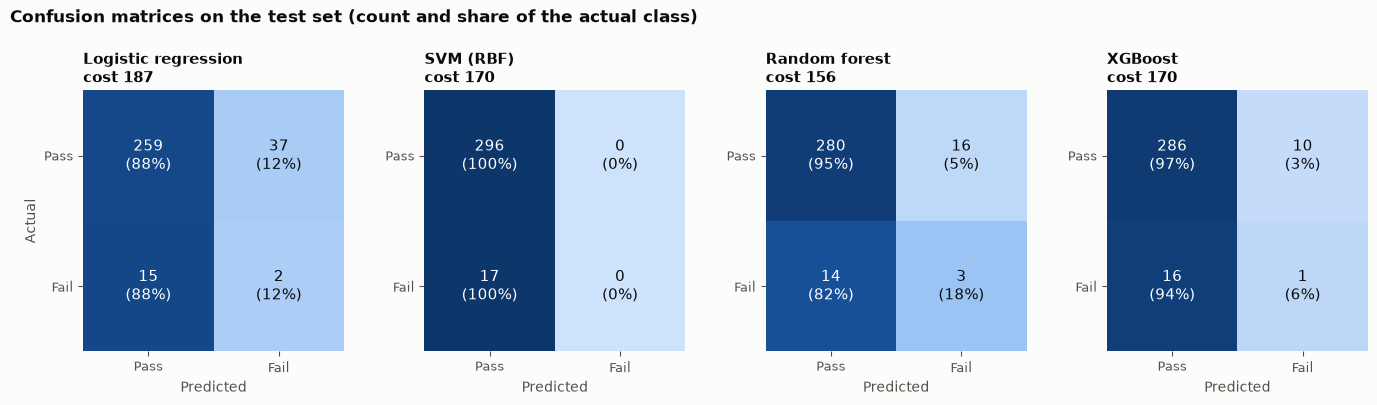

In [6]:
cmap = LinearSegmentedColormap.from_list('blues', SEQUENTIAL_BLUES)
fig, axes = plt.subplots(1, 4, figsize=(14, 3.8))
for ax, name in zip(axes, MODELS):
    r = test_results.set_index('model').loc[name]
    cm = np.array([[r['tn'], r['fp']], [r['fn'], r['tp']]])
    rates = cm / cm.sum(axis=1, keepdims=True)          # colour = share of the true class
    ax.imshow(rates, cmap=cmap, vmin=0, vmax=1)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f'{cm[i, j]}\n({rates[i, j]:.0%})', ha='center', va='center', fontsize=11,
                    color='white' if rates[i, j] > 0.55 else TEXT_PRIMARY)
    ax.set_xticks([0, 1], ['Pass', 'Fail']); ax.set_yticks([0, 1], ['Pass', 'Fail'])
    ax.set_xlabel('Predicted'); ax.set_ylabel('Actual' if name == MODELS[0] else '')
    ax.set_title(f'{name}\ncost {r["energy_cost"]:.0f}', fontsize=11)
    ax.grid(False)
    for s in ax.spines.values():
        s.set_visible(False)
fig.suptitle('Confusion matrices on the test set (count and share of the actual class)', x=0.01, ha='left',
             fontweight='bold')
fig.tight_layout(rect=(0, 0, 1, 0.92))
save_fig(fig, '05_confusion_matrices')
plt.show()

### 4.2 ROC and precision–recall curves (test set)

Dots mark each model's operating point at its 10 : 1 cost-optimal threshold.

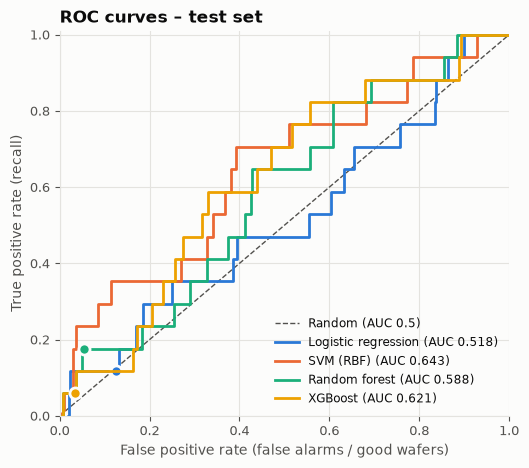

In [7]:
fig, ax = plt.subplots(figsize=(5.8, 5))
ax.plot([0, 1], [0, 1], color=REF_LINE_COLOR, linestyle='--', linewidth=1, label='Random (AUC 0.5)')
for name in MODELS:
    fpr, tpr, _ = roc_curve(y_test, test_scores[name])
    r = test_results.set_index('model').loc[name]
    ax.plot(fpr, tpr, color=MODEL_COLORS[name], label=f"{name} (AUC {r['roc_auc']:.3f})")
    ax.plot(r['fp'] / (r['fp'] + r['tn']), r['recall'], marker='o', markersize=8, color=MODEL_COLORS[name],
            markeredgecolor=SURFACE, markeredgewidth=2, linestyle='none')
ax.set_xlabel('False positive rate (false alarms / good wafers)')
ax.set_ylabel('True positive rate (recall)')
ax.set_xlim(0, 1); ax.set_ylim(0, 1.01)
ax.set_title('ROC curves – test set')
ax.legend(loc='lower right', fontsize=8.5)
save_fig(fig, '05_roc_curves')
plt.show()

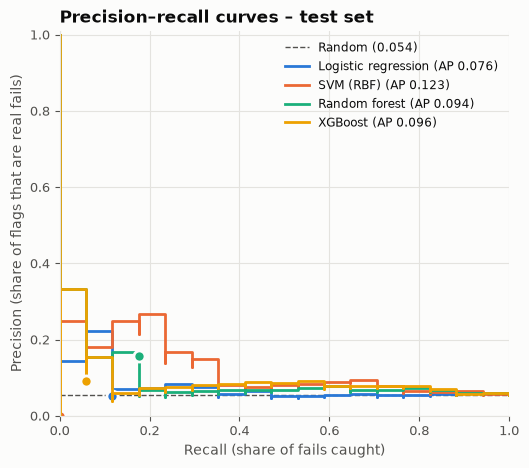

In [8]:
prevalence = y_test.mean()
fig, ax = plt.subplots(figsize=(5.8, 5))
ax.axhline(prevalence, color=REF_LINE_COLOR, linestyle='--', linewidth=1, label=f'Random ({prevalence:.3f})')
for name in MODELS:
    prec, rec, _ = precision_recall_curve(y_test, test_scores[name])
    r = test_results.set_index('model').loc[name]
    ax.step(rec, prec, where='post', color=MODEL_COLORS[name], label=f"{name} (AP {r['pr_auc']:.3f})")
    ax.plot(r['recall'], r['precision'], marker='o', markersize=8, color=MODEL_COLORS[name],
            markeredgecolor=SURFACE, markeredgewidth=2, linestyle='none')
ax.set_xlabel('Recall (share of fails caught)')
ax.set_ylabel('Precision (share of flags that are real fails)')
ax.set_xlim(0, 1); ax.set_ylim(0, 1.01)
ax.set_title('Precision–recall curves – test set')
ax.legend(loc='upper right', fontsize=8.5)
save_fig(fig, '05_pr_curves')
plt.show()

### 4.3 Energy cost vs threshold

Cost is shown **normalised** (÷ flag-nothing cost) so the training-OOF curve (1000 wafers, where the
threshold was chosen) and the test curve (313 wafers) share one scale. The dashed line is the chosen
threshold; if the two curves have their minimum in similar places, the threshold transferred well.

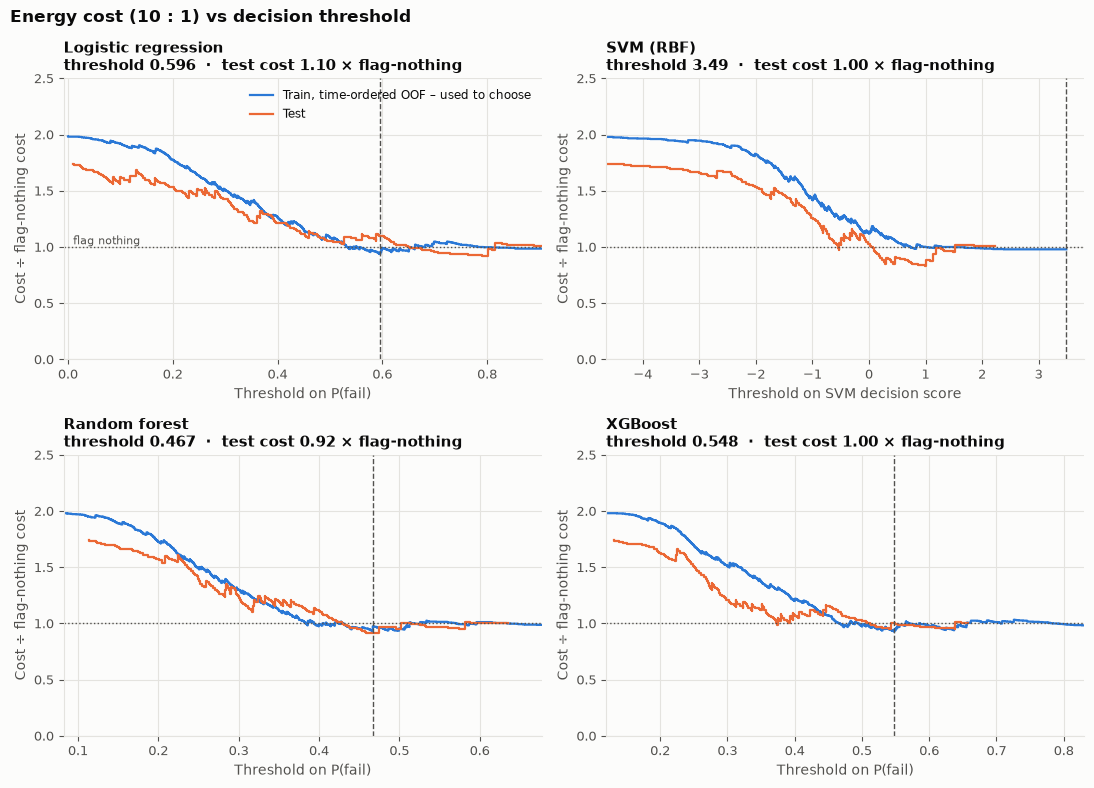

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, name in zip(axes.ravel(), MODELS):
    t = thresholds[(name, '10:1')]
    for label, y, s, color in [('Train, time-ordered OOF – used to choose', y_oof, oof[name], CATEGORICAL[0]),
                               ('Test', y_test, test_scores[name], CATEGORICAL[1])]:
        cc = cost_curve(y, s, C_FN, C_FP).iloc[1:]           # drop the +inf (flag nothing) row
        ax.plot(cc['threshold'], cc['cost'] / flag_nothing_cost(y, C_FN), color=color, label=label,
                drawstyle='steps-post', linewidth=1.6)
    ax.axvline(t, color=REF_LINE_COLOR, linestyle='--', linewidth=1)
    ax.axhline(1.0, color=REF_LINE_COLOR, linestyle=':', linewidth=1)
    test_norm = test_results.set_index('model').loc[name, 'normalized_cost']
    ax.set_title(f'{name}\nthreshold {t:.3g}  ·  test cost {test_norm:.2f} × flag-nothing', fontsize=10.5)
    ax.set_xlabel(f'Threshold on {SCORE_KIND[name]}')
    ax.set_ylabel('Cost ÷ flag-nothing cost')
    lo, hi = np.percentile(np.r_[oof[name], test_scores[name]], [0.5, 99.5])
    lo, hi = min(lo, t), max(hi, t)                   # always show the chosen threshold
    pad = 0.04 * (hi - lo)
    ax.set_xlim(lo - pad, hi + pad)
    ax.set_ylim(0, 2.5)
axes[0, 0].legend(loc='upper right', fontsize=8.5)
axes[0, 0].text(0.02, 1.0, 'flag nothing', transform=axes[0, 0].get_yaxis_transform(), va='bottom',
                fontsize=8, color=TEXT_SECONDARY)
fig.suptitle('Energy cost (10 : 1) vs decision threshold', x=0.01, ha='left', fontweight='bold')
fig.tight_layout()
save_fig(fig, '05_cost_vs_threshold')
plt.show()

## 5. Sensitivity analysis: 5 : 1 and 20 : 1

For each ratio the threshold is re-tuned on the OOF training scores (section 2) and applied to the test set.

In [10]:
sens = []
for name in MODELS:
    for ratio, (c_fn, c_fp) in COST_RATIOS.items():
        e = evaluate(y_test, test_scores[name], thresholds[(name, ratio)], c_fn, c_fp)
        sens.append({'model': name, 'ratio': ratio, 'threshold': e['threshold'], 'energy_cost': e['energy_cost'],
                     'normalized_cost': e['normalized_cost'], 'recall': e['recall'], 'precision': e['precision'],
                     'flagged': e['tp'] + e['fp'], 'fn': e['fn'], 'fp': e['fp']})
sens = pd.DataFrame(sens)
sens['rank'] = sens.groupby('ratio')['energy_cost'].rank(method='min').astype(int)

for ratio, (c_fn, c_fp) in COST_RATIOS.items():
    print(f'--- {ratio}  (flag nothing = {flag_nothing_cost(y_test, c_fn):.0f}, '
          f'flag everything = {flag_everything_cost(y_test, c_fp):.0f})')
    print(sens[sens['ratio'] == ratio].drop(columns='ratio').sort_values('rank').round(3).to_string(index=False))
    print()

--- 5:1  (flag nothing = 85, flag everything = 296)
              model  threshold  energy_cost  normalized_cost  recall  precision  flagged  fn  fp  rank
Logistic regression      0.960         85.0              1.0     0.0        0.0        0  17   0     1
          SVM (RBF)      3.489         85.0              1.0     0.0        0.0        0  17   0     1
      Random forest      0.722         85.0              1.0     0.0        0.0        0  17   0     1
            XGBoost      0.861         85.0              1.0     0.0        0.0        0  17   0     1

--- 10:1  (flag nothing = 170, flag everything = 296)
              model  threshold  energy_cost  normalized_cost  recall  precision  flagged  fn  fp  rank
      Random forest      0.467        156.0            0.918   0.176      0.158       19  14  16     1
          SVM (RBF)      3.489        170.0            1.000   0.000      0.000        0  17   0     2
            XGBoost      0.548        170.0            1.000   0.059 

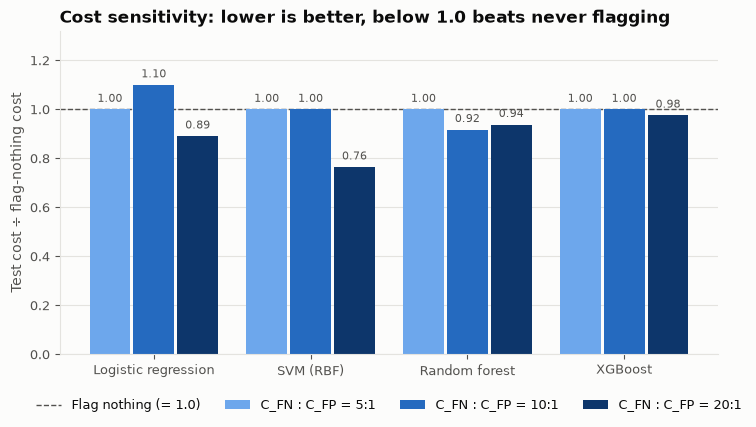

In [11]:
RATIO_COLORS = dict(zip(COST_RATIOS, [SEQUENTIAL_BLUES[2], SEQUENTIAL_BLUES[4], SEQUENTIAL_BLUES[6]]))
fig, ax = plt.subplots(figsize=(8.5, 4.2))
x = np.arange(len(MODELS)); w = 0.26
for j, ratio in enumerate(COST_RATIOS):
    vals = [sens[(sens.model == m) & (sens.ratio == ratio)]['normalized_cost'].iloc[0] for m in MODELS]
    pos = x + (j - 1) * (w + 0.02)
    ax.bar(pos, vals, width=w, color=RATIO_COLORS[ratio], label=f'C_FN : C_FP = {ratio}', zorder=2)
    for p, v in zip(pos, vals):
        ax.text(p, v + 0.02, f'{v:.2f}', ha='center', va='bottom', fontsize=8, color=TEXT_SECONDARY)
ax.axhline(1.0, color=REF_LINE_COLOR, linestyle='--', linewidth=1, label='Flag nothing (= 1.0)', zorder=1)
ax.set_xticks(x, MODELS)
ax.set_ylabel('Test cost ÷ flag-nothing cost')
ax.set_ylim(0, max(1.15, sens['normalized_cost'].max() * 1.2))
ax.set_title('Cost sensitivity: lower is better, below 1.0 beats never flagging')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.1), ncol=4, fontsize=9)
ax.grid(axis='x', visible=False)
save_fig(fig, '05_cost_sensitivity')
plt.show()

## 6. How certain is the ranking? (bootstrap)

The test set has only 17 failing wafers, so one extra caught or missed fault moves the cost by 10.
We resample the test wafers 2000 times (with replacement, predictions fixed) to get a 95% interval for each
model's normalised cost, and how often the lowest-cost model beats each other model.

In [12]:
rng = np.random.default_rng(RANDOM_STATE)
B = 2000
yt = y_test.to_numpy()
preds = {n: (test_scores[n] >= thresholds[(n, '10:1')]).astype(int) for n in MODELS}
boot = {n: np.empty(B) for n in MODELS}
for b in range(B):
    idx = rng.integers(0, len(yt), len(yt))
    yb = yt[idx]
    base = C_FN * yb.sum()
    for n in MODELS:
        pb = preds[n][idx]
        boot[n][b] = (C_FN * ((yb == 1) & (pb == 0)).sum() + C_FP * ((yb == 0) & (pb == 1)).sum()) / base

ci = pd.DataFrame({n: {'normalized_cost': test_results.set_index('model').loc[n, 'normalized_cost'],
                       'ci_low': np.percentile(boot[n], 2.5), 'ci_high': np.percentile(boot[n], 97.5),
                       'p_below_flag_nothing': (boot[n] < 1).mean()} for n in MODELS}).T
best_name = test_results.sort_values(['energy_cost', 'pr_auc'], ascending=[True, False]).iloc[0]['model']
ci['p_best_beats_this'] = [np.nan if n == best_name else (boot[best_name] < boot[n]).mean() for n in MODELS]
print(f'Lowest test cost at 10:1: {best_name}\n')
print(ci.astype(float).round(3).to_string())

Lowest test cost at 10:1: Random forest

                     normalized_cost  ci_low  ci_high  p_below_flag_nothing  p_best_beats_this
Logistic regression            1.100   0.912    1.370                 0.158              0.956
SVM (RBF)                      1.000   1.000    1.000                 0.000              0.762
Random forest                  0.918   0.716    1.136                 0.762                NaN
XGBoost                        1.000   0.864    1.118                 0.426              0.826


## 7. Shuffled vs time-ordered validation: drift over time

The first version of 04/05 used shuffled `StratifiedKFold(5)`; it gave ROC-AUC around 0.72, but on the test
set every model scored about 0.6. Shuffling mixes wafers from all periods, so each validation fold looks like
the training data, while the test set is the *latest* two weeks.

Below, each model is scored three ways: shuffled CV on the training set, time-ordered CV on the training set
(the OOF scores from section 1, which never touch the test set), and the test set. If time-ordered CV inside
the training set shows the same drop as the test set, the gap is caused by drift, not by a bug.

In [13]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
drift_rows = []
for name in MODELS:
    method = 'predict_proba' if hasattr(models[name], 'predict_proba') else 'decision_function'
    shuffled = cross_val_predict(clone(models[name]), X_train, y_train, cv=skf, method=method, n_jobs=1)
    shuffled = shuffled[:, 1] if shuffled.ndim == 2 else shuffled
    drift_rows.append({
        'model': name,
        'shuffled CV (train)': roc_auc_score(y_train, shuffled),
        'time-ordered CV (train)': roc_auc_score(y_oof, oof[name]),
        'test set': roc_auc_score(y_test, test_scores[name]),
    })
drift = pd.DataFrame(drift_rows).set_index('model')
print('ROC-AUC')
print(drift.round(3).to_string())

# How far did the 20 selected sensors move between train and test (in training standard deviations)?
fs = json.loads((MODELS_DIR / 'selected_features.json').read_text())['selected_features']
prep = joblib.load(MODELS_DIR / 'preprocessing_pipeline.joblib')
Z_tr, Z_te = prep.transform(X_train)[fs], prep.transform(X_test)[fs]
shift = (Z_te.mean() - Z_tr.mean()).abs().sort_values(ascending=False)
print(f'\nMean shift of the selected sensors, train -> test (training SDs): '
      f'median {shift.median():.2f}, largest {shift.index[0]} {shift.iloc[0]:.2f}')
print(shift.head(5).round(2).to_string())

ROC-AUC
                     shuffled CV (train)  time-ordered CV (train)  test set
model                                                                      
Logistic regression                0.714                    0.627     0.518
SVM (RBF)                          0.712                    0.577     0.643
Random forest                      0.754                    0.648     0.588
XGBoost                            0.753                    0.664     0.621



Mean shift of the selected sensors, train -> test (training SDs): median 0.24, largest f028 0.79
f028    0.79
f160    0.54
f059    0.43
f103    0.43
f510    0.40


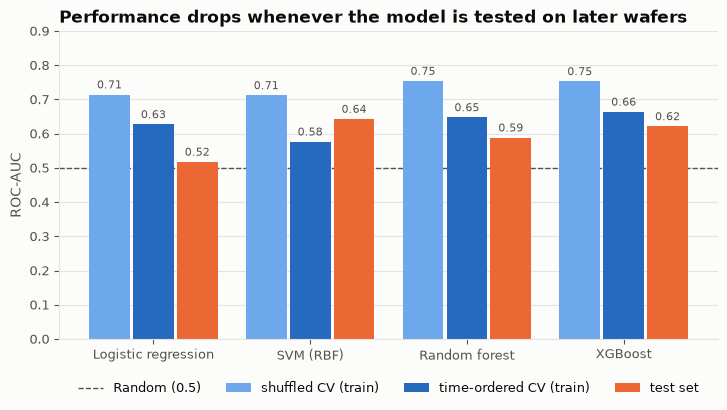

In [14]:
fig, ax = plt.subplots(figsize=(8.5, 4))
SETTINGS = list(drift.columns)
SET_COLORS = dict(zip(SETTINGS, [SEQUENTIAL_BLUES[2], SEQUENTIAL_BLUES[4], CATEGORICAL[1]]))
x = np.arange(len(MODELS)); w = 0.26
for j, setting in enumerate(SETTINGS):
    vals = drift.loc[MODELS, setting].to_numpy()
    pos = x + (j - 1) * (w + 0.02)
    ax.bar(pos, vals, width=w, color=SET_COLORS[setting], label=setting, zorder=2)
    for p, v in zip(pos, vals):
        ax.text(p, v + 0.01, f'{v:.2f}', ha='center', va='bottom', fontsize=8, color=TEXT_SECONDARY)
ax.axhline(0.5, color=REF_LINE_COLOR, linestyle='--', linewidth=1, label='Random (0.5)', zorder=1)
ax.set_xticks(x, MODELS)
ax.set_ylim(0, 0.9)
ax.set_ylabel('ROC-AUC')
ax.set_title('Performance drops whenever the model is tested on later wafers')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.1), ncol=4, fontsize=9)
ax.grid(axis='x', visible=False)
save_fig(fig, '05_drift_check')
plt.show()

**Reading the check**

- Shuffled CV scores every model at ROC-AUC 0.71–0.75. Time-ordered CV **inside the training set** (which
  never touches the test wafers) gives 0.58–0.66, and the test set 0.52–0.64.
- So the gap is not a bug in the test pipeline: whenever a model has to predict **later** wafers, it does
  worse. The process drifts over time, as EDA (monthly fail rate 22% → 9% → 3% → 6%) and 02 (test readings far
  outside the training range) also showed. The selected sensors shift by a median 0.24 training SDs between
  train and test, up to 0.79 for f028.
- Time-ordered CV is therefore the right way to validate this problem: its estimates are close to the test
  results, while shuffled CV over-promises.

## 8. Did time-ordered tuning help? (vs the earlier shuffled-CV version)

The earlier test results (models tuned and thresholds chosen with shuffled CV) are kept in
`outputs/05_test_results_shuffled_cv.csv`. Same test set, same cost metric.

In [15]:
old_path = OUTPUTS_DIR / '05_test_results_shuffled_cv.csv'
old = pd.read_csv(old_path).set_index('model')
new = test_results.set_index('model')
versus = pd.DataFrame({
    'cost (shuffled CV)': old['energy_cost'], 'cost (time-ordered CV)': new['energy_cost'],
    'PR-AUC (shuffled)': old['pr_auc'], 'PR-AUC (time-ordered)': new['pr_auc'],
    'ROC-AUC (shuffled)': old['roc_auc'], 'ROC-AUC (time-ordered)': new['roc_auc'],
    'recall (shuffled)': old['recall'], 'recall (time-ordered)': new['recall'],
}).loc[MODELS]
print(f'Test set, 10:1 (flag nothing = {nothing:.0f})')
print(versus.round(3).to_string())

old_s = pd.read_csv(OUTPUTS_DIR / '05_cost_sensitivity_shuffled_cv.csv')
both = sens.merge(old_s[['model', 'ratio', 'normalized_cost']], on=['model', 'ratio'], suffixes=('', '_shuffled'))
print('\nNormalised test cost (÷ flag nothing) by ratio: shuffled -> time-ordered')
print(both.pivot(index='model', columns='ratio', values='normalized_cost_shuffled')[list(COST_RATIOS)].round(2)
      .astype(str).add(' -> ')
      .add(both.pivot(index='model', columns='ratio', values='normalized_cost')[list(COST_RATIOS)].round(2).astype(str))
      .loc[MODELS].to_string())

Test set, 10:1 (flag nothing = 170)
                     cost (shuffled CV)  cost (time-ordered CV)  PR-AUC (shuffled)  PR-AUC (time-ordered)  ROC-AUC (shuffled)  ROC-AUC (time-ordered)  recall (shuffled)  recall (time-ordered)
model                                                                                                                                                                                          
Logistic regression               189.0                   187.0              0.107                  0.076               0.590                   0.518              0.176                  0.118
SVM (RBF)                         192.0                   170.0              0.084                  0.123               0.609                   0.643              0.353                  0.000
Random forest                     187.0                   156.0              0.088                  0.094               0.621                   0.588              0.235                  0.176
XGBo

**What changed with time-ordered tuning**

- **The best achievable cost at 10 : 1 improved:** 167 → 156 (best model), and random forest went from 187 to
  156. SVM went from 192 to 170, but only because its new threshold flags nothing; logistic regression barely
  changed (189 → 187) and XGBoost is about the same (167 → 170).
- **The validation estimates became honest.** Time-ordered CV now predicts test performance reasonably well
  (section 7), so model choices and thresholds are based on realistic numbers.
- **The thresholds transfer better:** for three of the four models the tuned threshold now costs less on the
  test set than the default threshold (before, XGBoost's default had beaten its tuned threshold).
- **It is not better everywhere.** At 20 : 1 the shuffled-CV models happened to do better on this test set
  (0.72–0.84 vs 0.76–0.98), and at 5 : 1 the new thresholds all choose to flag nothing.
- With only 17 failing test wafers, one fault more or less changes the cost by 10, so differences of
  10–20 cost units between versions are within the noise.

## 9. Final comparison and choice of model

**Selection rule (fixed before looking at the test set):** lowest test **energy cost at 10 : 1**; check that
the choice holds at 5 : 1 and 20 : 1; use PR-AUC as the tie-breaker.

In [16]:
rank_by_ratio = sens.pivot(index='model', columns='ratio', values='rank')[list(COST_RATIOS)]
final = test_results.set_index('model')[['imbalance', 'threshold', 'recall', 'precision', 'f1', 'f2', 'ber',
                                         'roc_auc', 'pr_auc', 'accuracy', 'energy_cost', 'normalized_cost']].copy()
final['cv_pr_auc (04)'] = [manifest['models'][m]['cv_pr_auc_mean'] for m in final.index]
final['cost_rank 5:1 / 10:1 / 20:1'] = [' / '.join(str(int(rank_by_ratio.loc[m, r])) for r in COST_RATIOS)
                                        for m in final.index]
final = final.sort_values(['energy_cost', 'pr_auc'], ascending=[True, False])

final.round(3).to_csv(OUTPUTS_DIR / '05_test_results.csv')
sens.round(4).to_csv(OUTPUTS_DIR / '05_cost_sensitivity.csv', index=False)
thr_table.round(4).to_csv(OUTPUTS_DIR / '05_thresholds.csv', index=False)
pd.DataFrame({'y_true': yt, **{n: test_scores[n] for n in MODELS}}, index=test_df.index) \
    .to_csv(OUTPUTS_DIR / '05_test_scores.csv')

pd.set_option('display.width', 200)
print(final.round(3).to_string())
print('\nSaved outputs/05_test_results.csv, 05_cost_sensitivity.csv, 05_thresholds.csv, 05_test_scores.csv')

                         imbalance  threshold  recall  precision     f1     f2    ber  roc_auc  pr_auc  accuracy  energy_cost  normalized_cost  cv_pr_auc (04) cost_rank 5:1 / 10:1 / 20:1
model                                                                                                                                                                                     
Random forest        Class weights      0.467   0.176      0.158  0.167  0.172  0.439    0.588   0.094     0.904        156.0            0.918           0.150                   1 / 1 / 3
SVM (RBF)            Class weights      3.489   0.000      0.000  0.000  0.000  0.500    0.643   0.123     0.946        170.0            1.000           0.105                   1 / 2 / 1
XGBoost              Class weights      0.548   0.059      0.091  0.071  0.063  0.487    0.621   0.096     0.917        170.0            1.000           0.156                   1 / 2 / 4
Logistic regression          SMOTE      0.596   0.118      0.051 

In [17]:
best = final.iloc[0]
runner = final.iloc[1]
chosen = {
    'model': best_name,
    'file': manifest['models'][best_name]['file'],
    'imbalance': manifest['models'][best_name]['imbalance'],
    'score': SCORE_KIND[best_name],
    'thresholds': {r: thresholds[(best_name, r)] for r in COST_RATIOS},
    'test_10to1': {k: (round(float(v), 4) if isinstance(v, (float, np.floating)) else v)
                   for k, v in best.items() if k not in ('cost_rank 5:1 / 10:1 / 20:1',)},
    'cost_rank_5_10_20': best['cost_rank 5:1 / 10:1 / 20:1'],
    'selection_rule': 'lowest test energy cost at 10:1; robustness checked at 5:1 and 20:1; PR-AUC tie-break',
}
(MODELS_DIR / 'final_model.json').write_text(json.dumps(chosen, indent=2, default=str))

print(f"BEST MODEL: {best_name} ({chosen['imbalance']})")
print(f"  Test energy cost {best['energy_cost']:.0f} vs flag nothing {nothing:.0f} "
      f"-> saves {1 - best['normalized_cost']:.0%} of the cost of not screening")
print(f"  Catches {best['recall']:.0%} of failing wafers; {best['precision']:.0%} of flagged wafers are real fails")
print(f"  Cost rank at 5:1 / 10:1 / 20:1: {best['cost_rank 5:1 / 10:1 / 20:1']}")
print(f"  Runner-up: {runner.name} (cost {runner['energy_cost']:.0f}); "
      f"{best_name} has lower cost in {ci.loc[runner.name, 'p_best_beats_this']:.0%} of bootstrap resamples")
print('Saved outputs/models/final_model.json')

BEST MODEL: Random forest (Class weights)
  Test energy cost 156 vs flag nothing 170 -> saves 8% of the cost of not screening
  Catches 18% of failing wafers; 16% of flagged wafers are real fails
  Cost rank at 5:1 / 10:1 / 20:1: 1 / 1 / 3
  Runner-up: SVM (RBF) (cost 170); Random forest has lower cost in 76% of bootstrap resamples
Saved outputs/models/final_model.json


### Verdict: random forest (class weights) is the best model, with a modest benefit

**Why random forest**

- **Lowest energy cost at the main 10 : 1 ratio:** 156, against 170 for SVM and XGBoost and 187 for logistic
  regression. It is the **only model clearly below the flag-nothing cost (170)**, saving 8%.
- **Most reliable of the four:** in the bootstrap its cost is below flag-nothing in 76% of resamples
  (XGBoost 43%), and it beats the other models in 76–96% of resamples.
- **Best operating point:** highest precision (0.158) and F1 (0.167), and the lowest balanced error rate
  (0.439). It flags only 19 of 313 wafers (6%), so false alarms stay low (16).
- **Consistent with tuning:** it was a close second in time-ordered CV (PR-AUC 0.149 vs XGBoost's 0.156).

**Limitations to state in the report**

- **It catches only 3 of the 17 failing wafers.** The benefit comes from very selective flagging, not from
  finding most faults.
- **The best model depends on the cost ratio.** At 5 : 1 no model is worth using: the cost-optimal choice for
  every model is to flag nothing. At 20 : 1, SVM is cheapest (0.77 × flag-nothing, catching 13 of 17 faults
  with 180 false alarms) and random forest ranks third (0.94).
- **Threshold-free metrics disagree with cost.** SVM has the best test ROC-AUC (0.643) and PR-AUC (0.123), but
  its 10 : 1 threshold flags nothing; ranking wafers well is not the same as being worth acting on.
- **The fault signal is weak and drifts over time** (section 7), so all savings are small and uncertain.

**Recommendation**

- Use **random forest with class weights** at the 10 : 1 cost-optimal threshold as the final model, and carry
  it into 06_Interpretation.
- If misses are judged ~20× as costly as false alarms, the **SVM** at its 20 : 1 threshold is the better choice.
- For real use: **retrain regularly** on recent wafers (the process drifts), **monitor sensor drift**, re-tune
  the threshold when the cost assumptions change, and collect more failing-wafer examples.